<a href="https://colab.research.google.com/github/aastha403/aasthamachinelearning/blob/main/aastha_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [7]:
from google.colab import files

uploaded = files.upload()

Saving fashion-mnist_train.csv.xlsx to fashion-mnist_train.csv.xlsx
Saving fashion-mnist_test.csv.xlsx to fashion-mnist_test.csv.xlsx


In [8]:
train_df = pd.read_excel("/content/fashion-mnist_train.csv.xlsx")
test_df = pd.read_excel("/content/fashion-mnist_test.csv.xlsx")

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Training dataset shape: (60000, 785)
Testing dataset shape: (10000, 785)


In [9]:
# Checking datasets
print("Training dataset:")
print(train_df.head())

print("\nTesting dataset:")
print(test_df.head())

print("\nTraining data types:")
print(train_df.dtypes.head())

print("\nTesting data types:")
print(test_df.dtypes.head())

Training dataset:
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      2       0       0       0       0       0       0       0       0   
1      9       0       0       0       0       0       0       0       0   
2      6       0       0       0       0       0       0       0       5   
3      0       0       0       0       1       2       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0        30        43         0   
3       0  ...         3         0         0         0         0         1   
4       0  ...         0         0         0         0         0         0   

   pixel781  pixel782  pixel783  pixel784  
0         0 

In [21]:
# Dataset Structures Data types and random samples


print("Training dataset columns:")
print(train_df.columns.tolist())

print("\nTesting dataset columns:")
print(test_df.columns.tolist())

Training dataset columns:
['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9', 'pixel10', 'pixel11', 'pixel12', 'pixel13', 'pixel14', 'pixel15', 'pixel16', 'pixel17', 'pixel18', 'pixel19', 'pixel20', 'pixel21', 'pixel22', 'pixel23', 'pixel24', 'pixel25', 'pixel26', 'pixel27', 'pixel28', 'pixel29', 'pixel30', 'pixel31', 'pixel32', 'pixel33', 'pixel34', 'pixel35', 'pixel36', 'pixel37', 'pixel38', 'pixel39', 'pixel40', 'pixel41', 'pixel42', 'pixel43', 'pixel44', 'pixel45', 'pixel46', 'pixel47', 'pixel48', 'pixel49', 'pixel50', 'pixel51', 'pixel52', 'pixel53', 'pixel54', 'pixel55', 'pixel56', 'pixel57', 'pixel58', 'pixel59', 'pixel60', 'pixel61', 'pixel62', 'pixel63', 'pixel64', 'pixel65', 'pixel66', 'pixel67', 'pixel68', 'pixel69', 'pixel70', 'pixel71', 'pixel72', 'pixel73', 'pixel74', 'pixel75', 'pixel76', 'pixel77', 'pixel78', 'pixel79', 'pixel80', 'pixel81', 'pixel82', 'pixel83', 'pixel84', 'pixel85', 'pixel86', 'pixel87', 'pixel88', 'pixe

In [22]:
# Checking data types
print("Training data types:")
print(train_df.dtypes.value_counts())

print("\nTesting data types:")
print(test_df.dtypes.value_counts())

Training data types:
int64    785
Name: count, dtype: int64

Testing data types:
int64    785
Name: count, dtype: int64


In [23]:
# Displaying 5 random samples as data
print("5 Random Training Samples:")
display(train_df.sample(5, random_state=42))

5 Random Training Samples:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
12628,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
37730,8,0,0,0,0,0,0,0,0,0,...,187,190,196,201,209,221,218,211,102,0
39991,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8525,5,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
8279,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


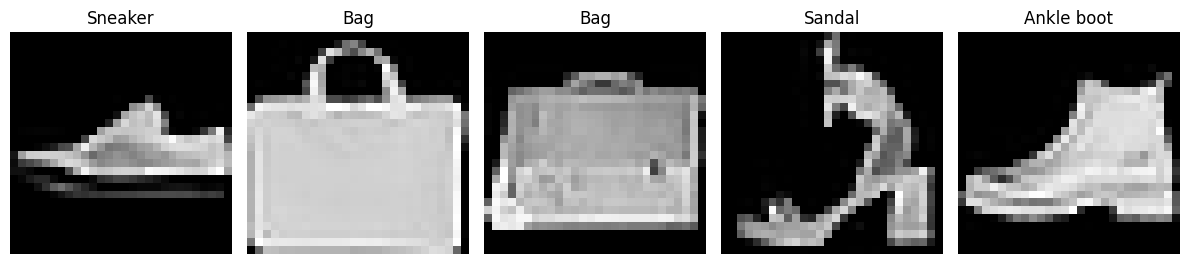

In [24]:
# Displaying 5 random images
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

random_samples = train_df.sample(5, random_state=42)

plt.figure(figsize=(12, 3))

for i, (_, row) in enumerate(random_samples.iterrows()):
    label = int(row["label"])
    image = row.drop("label").values.reshape(28, 28)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
# Missing Values
print("Missing values in training dataset:",
      train_df.isnull().sum().sum())

print("Missing values in testing dataset:",
      test_df.isnull().sum().sum())

Missing values in training dataset: 0
Missing values in testing dataset: 0


In [26]:
# Duplicate Values
print("Duplicate rows in training dataset:",
      train_df.duplicated().sum())

print("Duplicate rows in testing dataset:",
      test_df.duplicated().sum())

Duplicate rows in training dataset: 43
Duplicate rows in testing dataset: 1


In [28]:
# Checking Corrupt Pixel Values
train_pixels = train_df.drop("label", axis=1)
test_pixels = test_df.drop("label", axis=1)

print("Training minimum pixel value:",
      train_pixels.min().min())

print("Training maximum pixel value:",
      train_pixels.max().max())

print("Testing minimum pixel value:",
      test_pixels.min().min())

print("Testing maximum pixel value:",
      test_pixels.max().max())

Training minimum pixel value: 0
Training maximum pixel value: 255
Testing minimum pixel value: 0
Testing maximum pixel value: 255


In [29]:
# Checking Invalid Labels
print("Training labels:", sorted(train_df["label"].unique()))
print("Testing labels:", sorted(test_df["label"].unique()))

Training labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Testing labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [30]:
# Class Target Distribution
class_counts = train_df["label"].value_counts().sort_index()

for label, count in class_counts.items():
    print(label, "-", class_names[label], ":", count)

0 - T-shirt/top : 6000
1 - Trouser : 6000
2 - Pullover : 6000
3 - Dress : 6000
4 - Coat : 6000
5 - Sandal : 6000
6 - Shirt : 6000
7 - Sneaker : 6000
8 - Bag : 6000
9 - Ankle boot : 6000


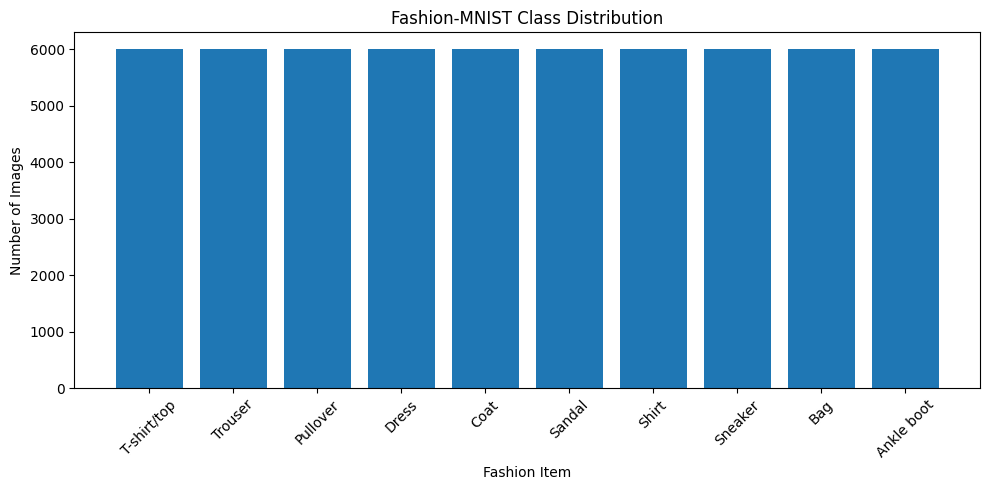

In [31]:
# Create class distribution plot
plt.figure(figsize=(10, 5))

plt.bar(class_names, class_counts.values)

plt.xlabel("Fashion Item")
plt.ylabel("Number of Images")
plt.title("Fashion-MNIST Class Distribution")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
# Seperate Features and labels
X = train_df.drop("label", axis=1).values
y = train_df["label"].values

X_test = test_df.drop("label", axis=1).values
y_test = test_df["label"].values

print("Training features:", X.shape)
print("Training labels:", y.shape)

print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)

Training features: (60000, 784)
Training labels: (60000,)
Test features: (10000, 784)
Test labels: (10000,)


In [33]:
# Create Validation Set
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (48000, 784)
Validation set: (12000, 784)
Test set: (10000, 784)


In [34]:
# Preparing Images for CNN
X_train = X_train.reshape(-1, 28, 28, 1)
X_val = X_val.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (48000, 28, 28, 1)
Validation: (12000, 28, 28, 1)
Testing: (10000, 28, 28, 1)


In [35]:
# Normalizing
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


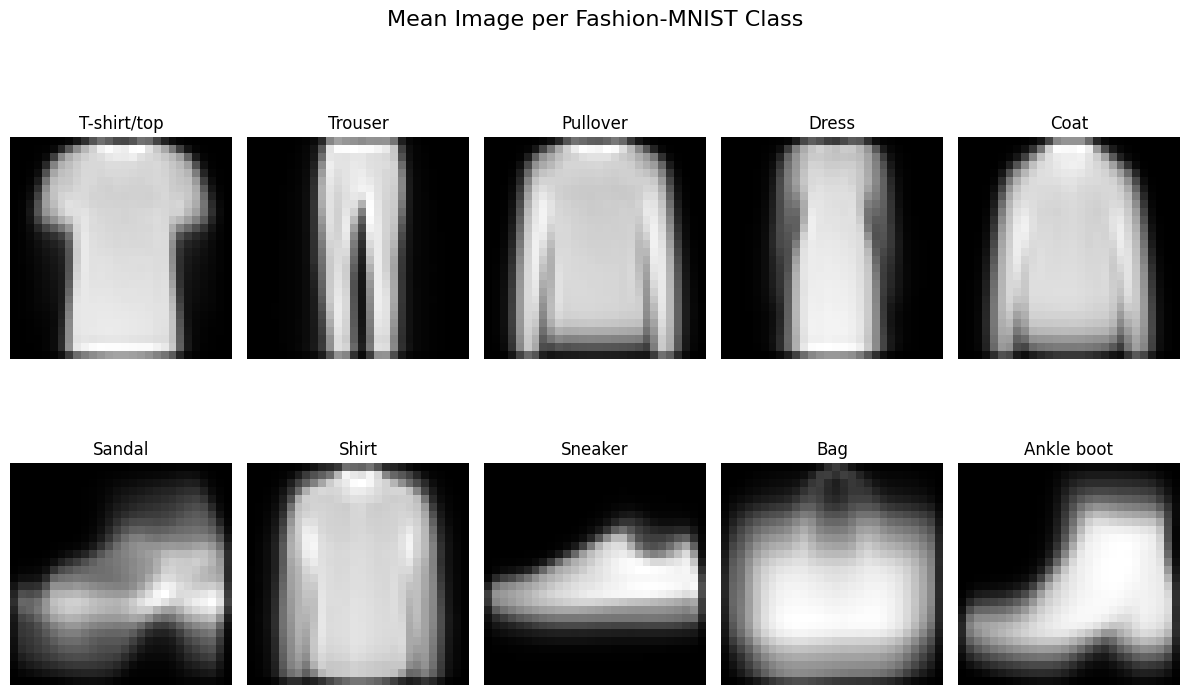

In [36]:
# Mean Image per class
# Class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Create a figure
plt.figure(figsize=(12, 8))

# Calculate and display mean image for each class
for class_id in range(10):

    # Select images belonging to the current class
    class_data = train_df[train_df["label"] == class_id]

    # Remove the label column
    pixels = class_data.drop("label", axis=1).values

    # Calculate mean pixel value
    mean_image = pixels.mean(axis=0)

    # Reshape into 28 x 28 image
    mean_image = mean_image.reshape(28, 28)

    # Display the mean image
    plt.subplot(2, 5, class_id + 1)
    plt.imshow(mean_image, cmap="gray")
    plt.title(class_names[class_id])
    plt.axis("off")

plt.suptitle("Mean Image per Fashion-MNIST Class", fontsize=16)
plt.tight_layout()
plt.show()